# Nerves and the macrophages around them

## Motivation

The heart is densely innervated, but nerves are thin: in a section most of them are a few micrometres across, far
below the size of a standard spatial-transcriptomics spot. At 2 µm resolution the FICTURE decode labels single
bins as neural, so we can ask questions that need the nerves themselves: where they run, which of them are
myelinated, and which cells sit next to them.

In this notebook we join neighbouring neural bins into **nerves** and follow them through four analyses: how
close nerves run to vessels (Fig 5 b–d), how myelination depends on nerve size (Fig 5 e–f), whether myelinated
nerves express more targets of drugs that cause peripheral neuropathy (Fig 5 g–h), and how the macrophages next to
nerves differ from the other macrophages of the myocardium (Fig 5 j–l).

## Dataset

We work with 11 Visium HD sections of the human left ventricle: eight sections from Berlin and three AH sections.
For every section the cell-typing pipeline (`scripts/substrate/`) has written the objects we start from:

| object | content | fields used here |
|---|---|---|
| 2 µm CMFLAG-clean `AnnData` (`h5ad_2um`) | 2 µm bins × genes after the spillover clean-up, raw counts | `X`, `obs["L3_label"]`, `obs["x_um"]`, `obs["y_um"]` |
| 8 µm CMFLAG-clean `AnnData` (`h5ad_8um`) | 8 µm bins for the section overview | `obs["L3_label"]`, `obsm["spatial"]` |
| FICTURE pixel decode (`.pixel.tsv.gz`) | one row per decode pixel | `X`, `Y` (µm), `K1` (code of the most probable Level-3 type) |
| Space Ranger 2 µm matrix (`square_002um`) | all in-tissue bins × features, raw counts | `X`, bin positions → `obsm["spatial"]` (µm) |
| H&E image and CMFLAG registration | microscopy image of the section and its affine map to bin coordinates | `M0`, `t0` |
| calibre table of the vessel analysis | one row per vessel structure | centre, diameter, calibre class |

The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the command-line scripts in
`scripts/nerve_macrophage/` and `figures/Fig5/` call the same functions.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All paths in the configuration are relative to the repository root, so we work
from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import statsmodels.formula.api as smf
import tifffile
from PIL import Image
from scipy import stats

import hhca
from hhca.config import fill, load_config, resolve_roots, section_path
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

Every parameter of the analysis is set in `config/nerve_macrophage.yaml`. We read the file once and look at the
values that define a nerve; the other blocks are shown where they are used.

In [2]:
cfg = load_config("nerve_macrophage")
section_names = cfg["slides"]["berlin"] + cfg["slides"]["ah"]
nerve = cfg["nerve"]
neural_type = nerve["neural_type"]
myelin_genes = nerve["myelin_genes"]
vascular_types = cfg["proximity"]["vascular_types"]
pd.Series(nerve, name="value").to_frame()

,value
neural_type,Neural Cells
unit,unique 2 um bin
linkage_um,6.0
min_bins,3
counts,member bins
myelin_genes,"[MBP, PLP1, MOG, MPZ, PMP22]"
myelinated_min,3
size_classes,"[3, 6, 10, 20, 40, 10000]"
gene_universe,panel_intersection


## Loading data

The 2 µm bins of a section are an `AnnData` with raw counts and one Level-3 label per bin. We open all 11
sections without loading the count matrices into memory.

In [3]:
sections = {name: ad.read_h5ad(section_path(cfg, "h5ad_2um", name), backed="r") for name in section_names}
section = cfg["fields"]["slide"]
adata = sections[section]
adata

AnnData object with n_obs × n_vars = 3626127 × 18085 backed at 'results/substrate/clean_h5ad/h5ad_2um_CMFLAG_clean/VS_BO_HDZ150319_34_myo.h5ad'
    obs: 'L3_label', 'gcert', 'posterior_max', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'build', 'cmflag'

We walk through each step on one section, `VS_BO_HDZ150319_34_myo`, a mid-myocardial section, and then run it on
all 11. How many of the bins of a section are neural?

In [4]:
rows = []
for bins in sections.values():
    n_neural = (bins.obs["L3_label"] == neural_type).sum()
    rows.append({"2 µm bins": bins.n_obs, "neural bins": n_neural})
n_bins = pd.DataFrame(rows, index=list(sections))
n_bins["% neural"] = (100 * n_bins["neural bins"] / n_bins["2 µm bins"]).round(2)
n_bins

,2 µm bins,neural bins,% neural
VS_BO_HDZ150319_34_myo,3626127,5569,0.15
VS_BO_2024BH-008_myo,3367499,553,0.02
VS_CA_H0054LV_henricke_epi,7633492,3360,0.04
VS_CA_H0054LV_henricke_myo,7701469,3108,0.04
VS_CA_H0054LV_henricke_endo,7015351,8851,0.13
VS_CA_H0063LV_henricke_epi,7442651,1429,0.02
VS_CA_H0063LV_henricke_myo,6798677,3300,0.05
VS_CA_H0063LV_henricke_endo,5739584,9520,0.17
VS_AH9_LV_FW_epi,5476477,9948,0.18
VS_AH10_LV_mid_endo,6691420,8245,0.12


To see the tissue, we load the 8 µm `AnnData` of our section and plot its Level-3 labels in tissue coordinates,
in the colours of the spatial panels (`style.SPATIAL`).

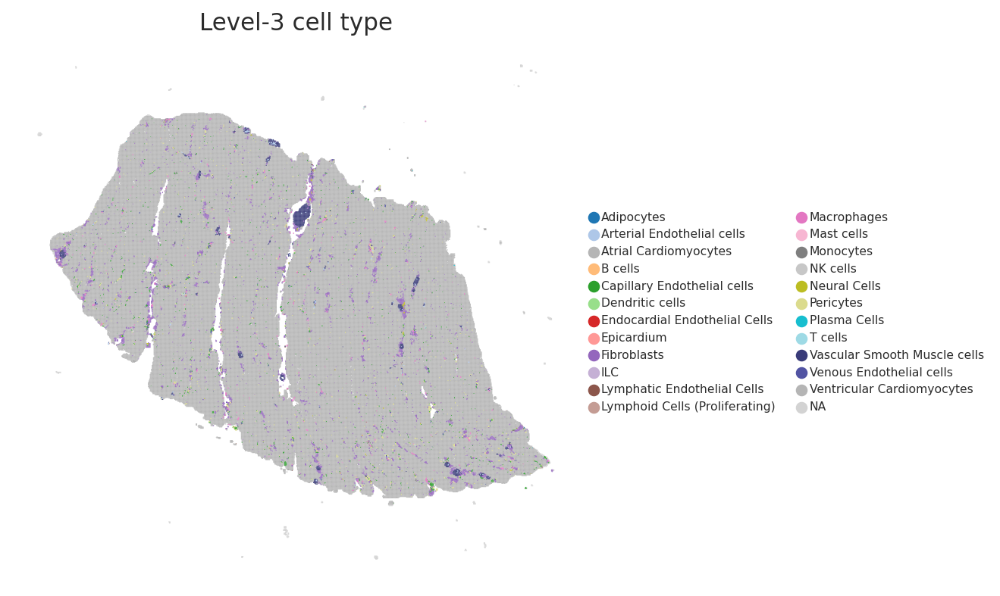

In [5]:
tissue = sc.read_h5ad(section_path(cfg, "h5ad_8um", section))
style.set_colors(tissue, "L3_label", style.SPATIAL)
with plt.rc_context({"figure.figsize": (6, 6)}):
    ax = sc.pl.embedding(
        tissue, basis="spatial", color="L3_label", size=1, legend_fontsize=7, title="Level-3 cell type", show=False
    )
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Neural bins are rare, well below 1% of every section, and scattered over the whole tissue.

## Calling nerves

A single neural bin can be a stray label; a nerve is a group of them. `hhca.tl.call_nerves` links neural bins that
are closer than 6 µm and calls every group of at least three linked bins a nerve. It returns one row per neural
bin, indexed by its row in `adata`, with the id of its nerve (`-1` for a bin outside any nerve) and the number of
bins it is linked with (`comp_size`).

In [6]:
linkage_um = nerve["linkage_um"]
min_nerve_bins = nerve["min_bins"]
neural = hhca.tl.call_nerves(adata, neural_type=neural_type, linkage_um=linkage_um, min_bins=min_nerve_bins)
in_a_nerve = neural["nerve"] >= 0
n_in_nerves = in_a_nerve.sum()
n_nerves = neural["nerve"].max() + 1
print(f"{len(neural):,} neural bins, {n_in_nerves:,} of them in {n_nerves} nerves")
neural.head()

5,569 neural bins, 5,111 of them in 312 nerves


,x_um,y_um,nerve,comp_size
2024,1627.699951,6363.600098,0,3
2025,1627.699951,6367.600098,0,3
2117,1629.699951,6367.600098,0,3
5107,1679.599976,6331.500000,1,67
5246,1681.599976,6329.500000,1,67


Let's look at the neural bins of the section, coloured by whether they belong to a nerve.

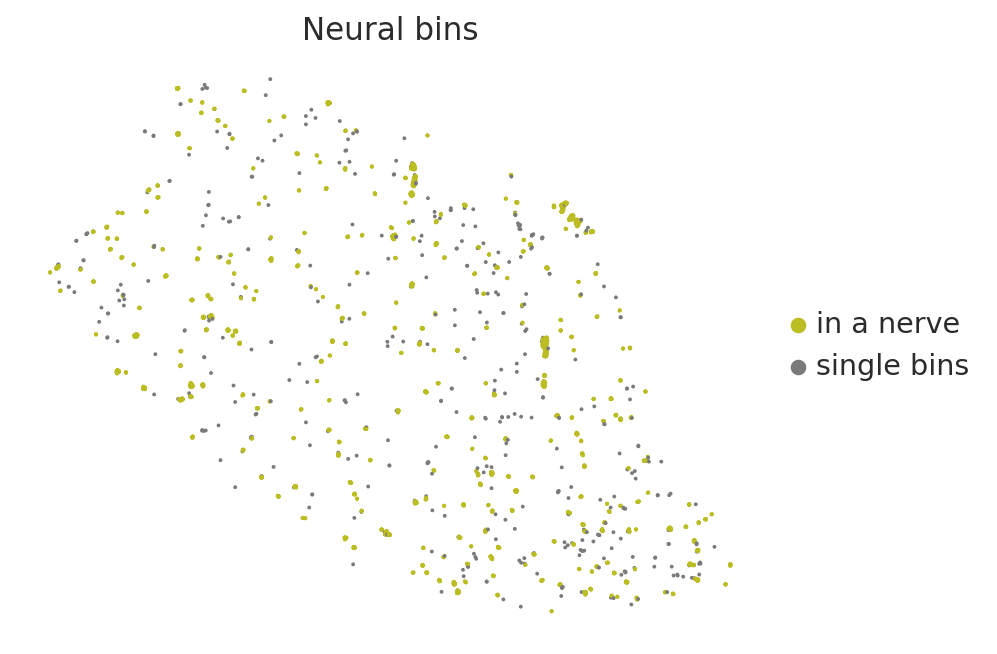

In [7]:
neural_map = adata[neural.index].to_memory()
neural_map.obsm["spatial"] = neural_map.obs[["x_um", "y_um"]].to_numpy()
neural_map.obs["nerve"] = pd.Categorical(np.where(in_a_nerve, "in a nerve", "single bins"))
style.set_colors(neural_map, "nerve", style.NERVE_BINS)
with plt.rc_context({"figure.figsize": (6, 6)}):
    ax = sc.pl.embedding(neural_map, basis="spatial", color="nerve", size=12, title="Neural bins", show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Most neural bins lie in nerves, which appear as short strings and compact groups; the single bins are spread
evenly between them.

A nerve of a few bins holds few transcripts, so we treat each nerve as one profile. `hhca.tl.nerve_pseudobulk`
sums the counts of the member bins of every nerve and returns an `AnnData` of nerves × genes. Its `obs` holds the
number of bins, the summed counts of the five myelin genes (`myelin_total`), the centroid and the distance to the
nearest vascular bin.

In [8]:
nerves = hhca.tl.nerve_pseudobulk(adata, neural, myelin_genes, vascular_types)
nerves

AnnData object with n_obs × n_vars = 312 × 18085
    obs: 'nerve', 'n_bins', 'myelin_total', 'total_counts', 'cx', 'cy', 'd_vessel_um'
    layers: 'counts'

In [9]:
nerves.obs.head()

,nerve,n_bins,myelin_total,total_counts,cx,cy,d_vessel_um
0,0,3,0.0,6.0,1628.366618,6366.266764,42.090540
1,1,67,2.0,357.0,1693.029827,6321.832782,2.000000
2,2,6,0.0,17.0,1717.300049,6527.066569,4.472136
3,3,4,0.0,62.0,1894.199951,6341.299805,20.813837
4,4,7,0.0,43.0,2004.614258,6010.114188,2.758640


We now call the nerves of every section and concatenate their profiles; `slide` names the section of a nerve.

In [10]:
neural_bins = {}
profiles = {}
for name, bins in sections.items():
    neural_bins[name] = hhca.tl.call_nerves(
        bins, neural_type=neural_type, linkage_um=linkage_um, min_bins=min_nerve_bins
    )
    profiles[name] = hhca.tl.nerve_pseudobulk(bins, neural_bins[name], myelin_genes, vascular_types)
nerves = ad.concat(profiles, label="slide", index_unique="__")
n_sections = nerves.obs["slide"].nunique()
print(f"{nerves.n_obs:,} nerves on {n_sections} sections, {nerves.n_vars:,} genes")
nerves.obs.groupby("slide", observed=True)["n_bins"].agg(nerves="size", median_bins="median", largest="max")

4,678 nerves on 11 sections, 18,085 genes


,nerves,median_bins,largest
slide,,,
VS_BO_HDZ150319_34_myo,312,8.0,396
VS_BO_2024BH-008_myo,42,5.0,65
VS_CA_H0054LV_henricke_epi,284,5.0,218
VS_CA_H0054LV_henricke_myo,300,5.0,101
VS_CA_H0054LV_henricke_endo,519,7.0,339
VS_CA_H0063LV_henricke_epi,122,5.0,170
VS_CA_H0063LV_henricke_myo,160,6.0,729
VS_CA_H0063LV_henricke_endo,334,6.0,2362
VS_AH9_LV_FW_epi,949,5.0,1556


The 11 sections hold 4,678 nerves, from 42 to 1,116 per section. A typical nerve has 5 to 8 bins, and the largest
one 2,508.

## A nerve next to a vessel

What does a nerve look like on the histology? For our section the H&E image is registered to the bin coordinates
by the CMFLAG pipeline, as an affine map (`M0`, `t0`) from micrometres to image pixels. We open the image without
reading it into memory and load the map, the CytAssist image of the section, which shares the coordinates of the
bins, and the positions of all in-tissue 2 µm bins.

In [11]:
fields = cfg["fields"]
roots = resolve_roots(cfg)
he = tifffile.memmap(fill(fields["tif"], roots), mode="r")
registration = np.load(section_path(cfg, "registration", section))
um_to_px = (registration["M0"], registration["t0"])
cytassist_dir = fill(fields["cytassist_dir"], roots)
with open(f"{cytassist_dir}/scalefactors_json.json") as handle:
    scalefactors = json.load(handle)
cytassist = np.asarray(Image.open(f"{cytassist_dir}/tissue_hires_image.png").convert("RGB"))
cytassist_um_per_px = float(scalefactors["microns_per_pixel"]) / float(scalefactors["tissue_hires_scalef"])
tissue_xy = hhca.io.read_tissue_positions(section_path(cfg, "spaceranger", section))
print(f"H&E {he.shape[1]:,} × {he.shape[0]:,} px, CytAssist image at {cytassist_um_per_px:.2f} µm per pixel")

H&E 16,759 × 12,385 px, CytAssist image at 4.61 µm per pixel


The registration is global, so a field of 100 µm can still be off by a few micrometres.
`hhca.tl.registration_offset` corrects this locally: it compares the H&E with the CytAssist image in a tile around
the field and returns the shift between the two. The shift is applied when the match is good enough and the shift
small. Here is the field of Fig 5 b, 120 µm around a nerve:

In [12]:
tile_half_um = fields["registration_tile_half_um"]
resolution_um = fields["registration_res_um"]
max_error = fields["registration_err_max"]
max_shift_um = fields["registration_offset_cap_um"]
nerve_centre = fields["b"]["centre"]
nerve_side_um = fields["b"]["side_um"]
offset = hhca.tl.registration_offset(
    he,
    um_to_px,
    cytassist,
    cytassist_um_per_px,
    nerve_centre,
    half_um=tile_half_um,
    res_um=resolution_um,
    max_error=max_error,
    max_um=max_shift_um,
)
offset

{'offset_um': [1.7999999523162842, 1.2000000476837158],
 'error': 0.1938716322183609,
 'applied': True,
 'shift': (1.7999999523162842, 1.2000000476837158)}

`hhca.tl.registered_field` then cuts the field out of the section: the H&E at its native resolution, the 2 µm
bins with their Level-3 label, and the in-tissue bins that have no label (no decode pixel, or removed by the
clean-up).

In [13]:
nerve_window = hhca.tl.square_window(nerve_centre, nerve_side_um)
nerve_field = hhca.tl.registered_field(adata, he, um_to_px, nerve_window, offset["shift"], tissue_xy=tissue_xy)
crop_shape = nerve_field["he"].shape
n_unlabelled = len(nerve_field["ux"])
print(f"H&E crop {crop_shape}, {n_unlabelled} of {nerve_field['n_tissue']} bins without a label")
pd.Series(nerve_field["blab"]).value_counts().to_frame("2 µm bins")

H&E crop (317, 317, 3), 947 of 3839 bins without a label


,2 µm bins
Ventricular Cardiomyocytes,1018
Fibroblasts,760
Vascular Smooth Muscle cells,684
Neural Cells,428
Arterial Endothelial cells,81
Macrophages,79
Pericytes,15
Lymphatic Endothelial Cells,7
Monocytes,1
Lymphoid Cells (Proliferating),1


`hhca.pl.nerve_on_he` draws Fig 5 b: the H&E of the field, and below it the same field with the neural bins
filled.

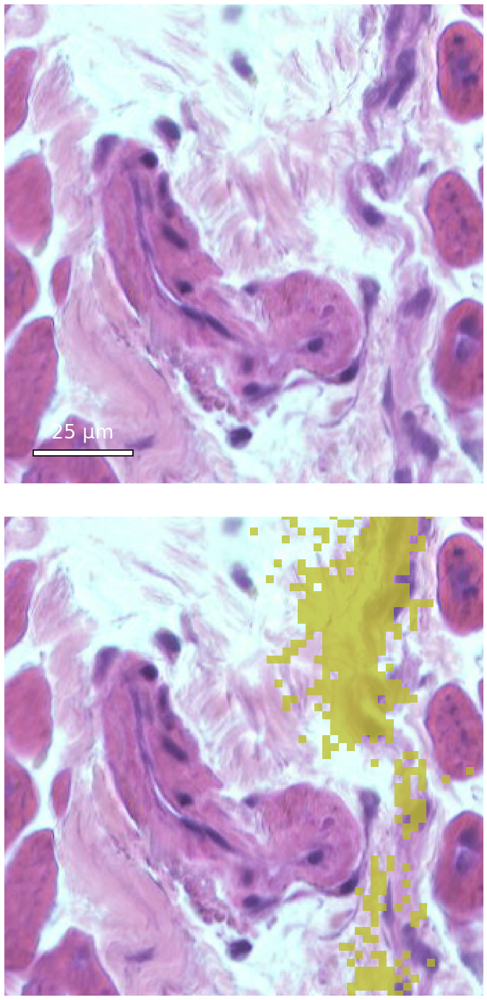

In [14]:
fig = hhca.pl.nerve_on_he(nerve_field, neural_type)

The 428 neural bins of the field trace a nerve that runs along a vessel: 684 smooth-muscle and 81 arterial
endothelial bins lie in the same 120 µm.

## Nerves and vessels in a larger window

Is this neighbourhood typical? We first look at a window of 800 µm with all its neural and vascular bins, the
window of Fig 5 c. Vascular bins are those of the five vascular types of the configuration.

In [15]:
x0, x1, y0, y1 = fields["c"]["window"]
window_centre = ((x0 + x1) / 2, (y0 + y1) / 2)
offset = hhca.tl.registration_offset(
    he,
    um_to_px,
    cytassist,
    cytassist_um_per_px,
    window_centre,
    half_um=tile_half_um,
    res_um=resolution_um,
    max_error=max_error,
    max_um=max_shift_um,
)
vessel_window = hhca.tl.registered_field(adata, he, um_to_px, (x0, x1, y0, y1), offset["shift"], margin_um=0.0)
labels = pd.Series(vessel_window["blab"])
is_neural = labels == neural_type
is_vascular = labels.isin(vascular_types)
kind = np.select([is_neural, is_vascular], ["neural", "vascular"], default="other")
pd.Series(kind).value_counts().to_frame("2 µm bins")

,2 µm bins
other,136485
vascular,4106
neural,123


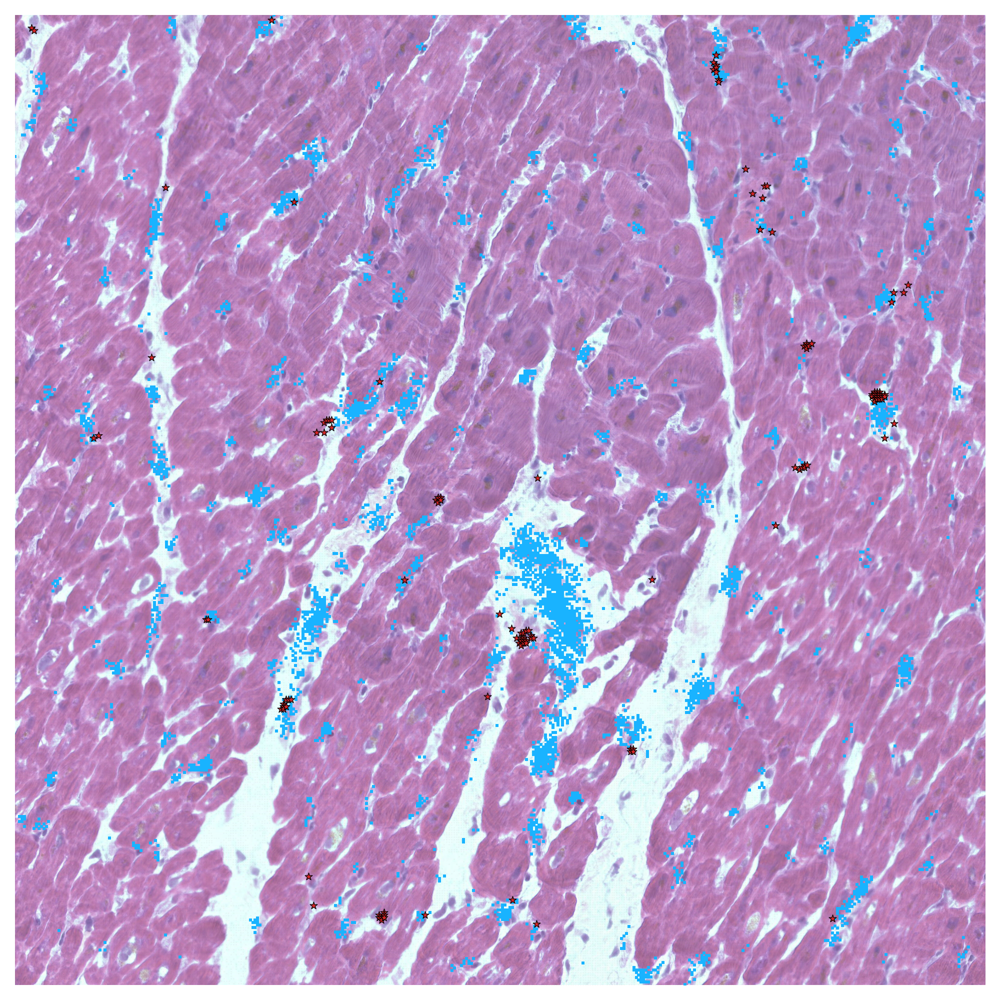

In [16]:
fig = hhca.pl.nerves_and_vessels(vessel_window, vascular_types, neural_type)

In the window, 123 neural bins (red stars) lie among 4,106 vascular bins (blue squares), and most of them sit
directly on a vessel.

## Distance of nerves to vessels

To put a number on this, we measure for every nerve the shortest distance from one of its bins to a vascular bin.
A large nerve has more bins and is therefore closer to something by chance, so the distance alone says little. As
a background, `hhca.tl.nerve_vessel_distance` moves the bins of each nerve together to random positions of the
same section, five times per nerve, and measures the same distance there. The placements keep the shape and the
size of the nerve.

In [17]:
proximity = cfg["proximity"]
distances = hhca.tl.nerve_vessel_distance(
    sections,
    neural_bins,
    vascular_types,
    neural_type,
    placements=proximity["placements_per_nerve"],
    seed=proximity["seed"],
    max_tries=proximity["max_tries"],
    min_on_tissue=proximity["min_on_tissue"],
    on_tissue_um=proximity["on_tissue_um"],
)
distances["sections"]

,slide,n_nerves,placements_kept,placements_failed
0,VS_BO_HDZ150319_34_myo,312,1560,0
1,VS_BO_2024BH-008_myo,42,210,0
2,VS_CA_H0054LV_henricke_epi,284,1420,0
3,VS_CA_H0054LV_henricke_myo,300,1500,0
4,VS_CA_H0054LV_henricke_endo,519,2595,0
5,VS_CA_H0063LV_henricke_epi,122,610,0
6,VS_CA_H0063LV_henricke_myo,160,800,0
7,VS_CA_H0063LV_henricke_endo,334,1670,0
8,VS_AH9_LV_FW_epi,949,4745,0
9,VS_AH10_LV_mid_endo,540,2700,0


The function returns three tables: one row per nerve, one row per placement, and the summary per section above.
We put nerves and placements into one long table and compare the two distributions.

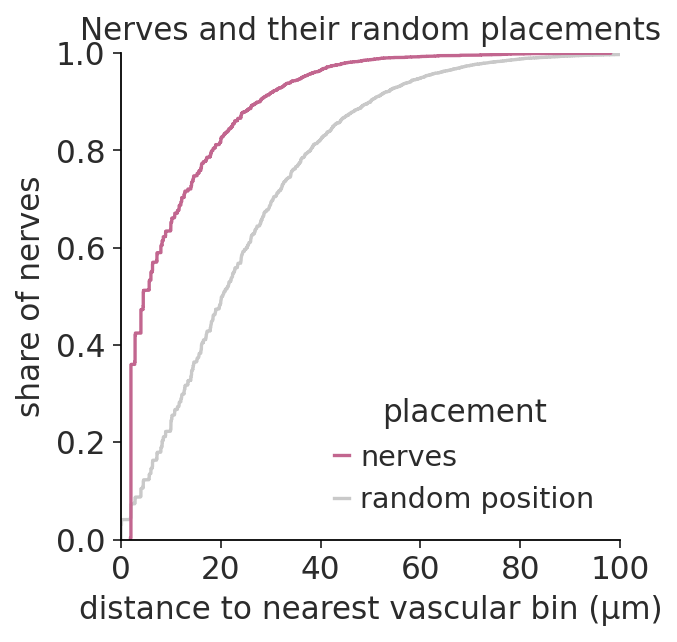

In [18]:
placed = pd.concat(
    {"nerves": distances["nerves"], "random position": distances["placements"]}, names=["placement"]
).reset_index(level="placement")
ax = sns.ecdfplot(placed, x="d_vessel_um", hue="placement", palette=style.NERVE_PLACEMENT)
ax.set(xlim=(0, 100), xlabel="distance to nearest vascular bin (µm)", ylabel="share of nerves")
ax.set_title("Nerves and their random placements")
plt.show()

In [19]:
near_um = proximity["near_um"]
summary = placed.groupby("placement")["d_vessel_um"].agg(n="size", median_um="median")
for near in near_um:
    within = placed["d_vessel_um"] <= near
    summary[f"% within {near} µm"] = 100 * within.groupby(placed["placement"]).mean()
closer = stats.mannwhitneyu(
    distances["nerves"]["d_vessel_um"], distances["placements"]["d_vessel_um"], alternative="less"
)
print(f"one-sided Mann-Whitney U = {closer.statistic:.0f}, p = {closer.pvalue:.1e}")
summary.round(1)

one-sided Mann-Whitney U = 26494541, p = 0.0e+00


,n,median_um,% within 8 µm,% within 16 µm
placement,,,,
nerves,4678,4.5,60.0,76.0
random position,23390,20.4,18.6,38.6


Does this hold for small and large nerves alike? `hhca.tl.proximity_by_size` gives the same numbers per size
class.

In [20]:
hhca.tl.proximity_by_size(distances["nerves"], distances["placements"], nerve["size_classes"], near_um[0]).round(1)

,size_class,n_nerves,median_nerve_um,median_background_um,pct8_nerve,pct8_background
0,3–5,2263,6.4,22.4,53.2,14.5
1,6–9,1226,4.5,20.9,61.0,17.2
2,10–19,811,2.8,18.8,68.3,20.8
3,20–39,227,2.0,15.2,76.2,31.1
4,≥40,151,2.0,4.5,84.1,60.5


`hhca.pl.nerve_vessel_distance` draws Fig 5 d: the two distributions with their medians and the distances of
8 and 16 µm.

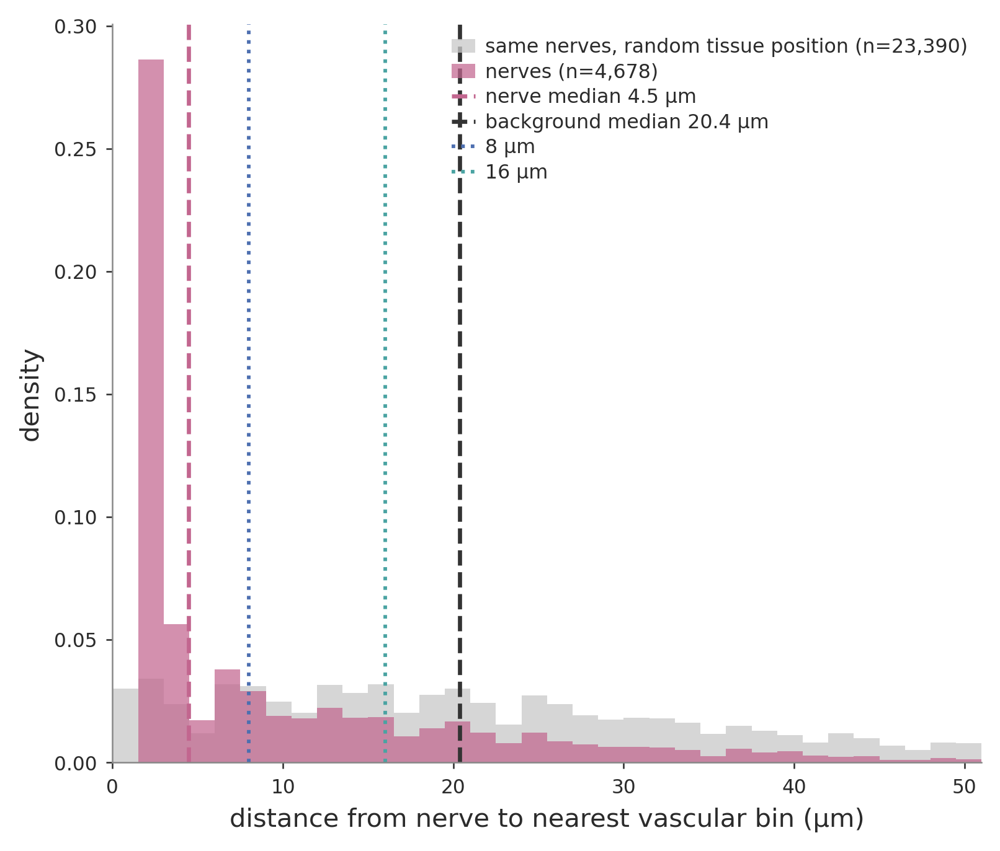

In [21]:
fig = hhca.pl.nerve_vessel_distance(distances["nerves"]["d_vessel_um"], distances["placements"]["d_vessel_um"], near_um)

Nerves run along vessels. The median nerve lies 4.5 µm from the nearest vascular bin, the same shapes at random
positions 20.4 µm; 60.0% of the nerves are within 8 µm of a vessel, against 18.6% of the 23,390 placements (the
p value is below the smallest number the test can return). The difference is there in every size class.

## Myelination and nerve size

Myelinated fibres conduct fast and belong to larger nerves. We score the myelination of a nerve by the summed
counts of five myelin genes (*MBP*, *PLP1*, *MOG*, *MPZ*, *PMP22*) and call a nerve myelinating from three counts
on. `hhca.tl.nerve_myelination` adds this call, the size class and the score `logmy = log1p(myelin_total)` to the
per-nerve table.

In [22]:
myelination = hhca.tl.nerve_myelination(nerves.obs, nerve["myelinated_min"], nerve["size_classes"])
myelination.head()

,n_bins,myelin_total,slide,myelinating,szbin,logmy
0,3,0.0,VS_BO_HDZ150319_34_myo,False,3–5,0.000000
1,67,2.0,VS_BO_HDZ150319_34_myo,False,≥40,1.098612
2,6,0.0,VS_BO_HDZ150319_34_myo,False,6–9,0.000000
3,4,0.0,VS_BO_HDZ150319_34_myo,False,3–5,0.000000
4,7,0.0,VS_BO_HDZ150319_34_myo,False,6–9,0.000000


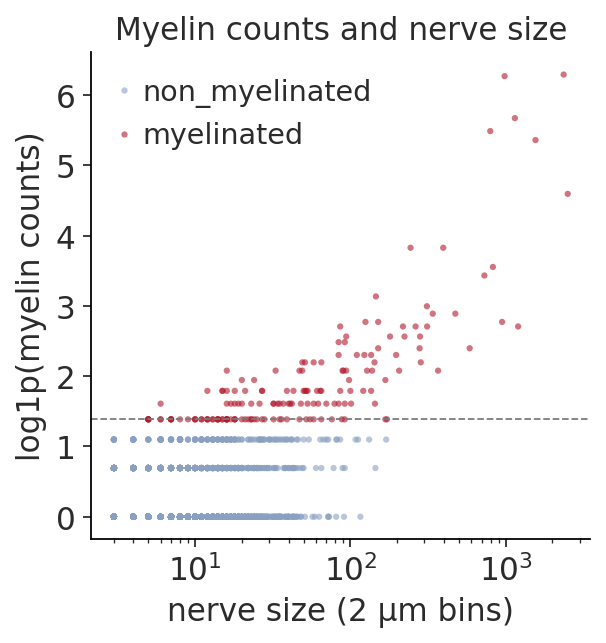

In [23]:
myelination["call"] = np.where(myelination["myelinating"], "myelinated", "non_myelinated")
ax = sns.scatterplot(
    myelination, x="n_bins", y="logmy", hue="call", palette=style.MYELINATION, s=8, linewidth=0, alpha=0.6
)
myelinated_level = np.log1p(nerve["myelinated_min"])
ax.axhline(myelinated_level, color=style.MUTED, lw=0.8, ls="--")
ax.set(xscale="log", xlabel="nerve size (2 µm bins)", ylabel="log1p(myelin counts)")
ax.set_title("Myelin counts and nerve size")
ax.legend(title="")
plt.show()

Myelin counts appear almost only in the larger nerves. We count the myelinating nerves per size class and test
the dependence on size with a Kruskal–Wallis test over the classes and a rank correlation.

In [24]:
by_size = myelination.groupby("szbin", observed=True).agg(nerves=("n_bins", "size"), myelinating=("myelinating", "sum"))
by_size["% myelinating"] = (100 * by_size["myelinating"] / by_size["nerves"]).round(1)
scores_by_size = [scores.to_numpy() for _, scores in myelination.groupby("szbin", observed=True)["logmy"]]
kruskal = stats.kruskal(*scores_by_size)
spearman = stats.spearmanr(myelination["n_bins"], myelination["myelin_total"])
print(f"Kruskal-Wallis H = {kruskal.statistic:.1f}, p = {kruskal.pvalue:.1e}")
print(f"Spearman rho = {spearman.statistic:.2f}, p = {spearman.pvalue:.1e}")
by_size

Kruskal-Wallis H = 807.4, p = 1.9e-173
Spearman rho = 0.32, p = 2.2e-112


,nerves,myelinating,% myelinating
szbin,,,
3–5,2263,5,0.2
6–9,1226,9,0.7
10–19,811,35,4.3
20–39,227,28,12.3
≥40,151,88,58.3


`hhca.pl.myelination_by_size` draws Fig 5 e: the score of every nerve by size class, with the share of
myelinating nerves on top.

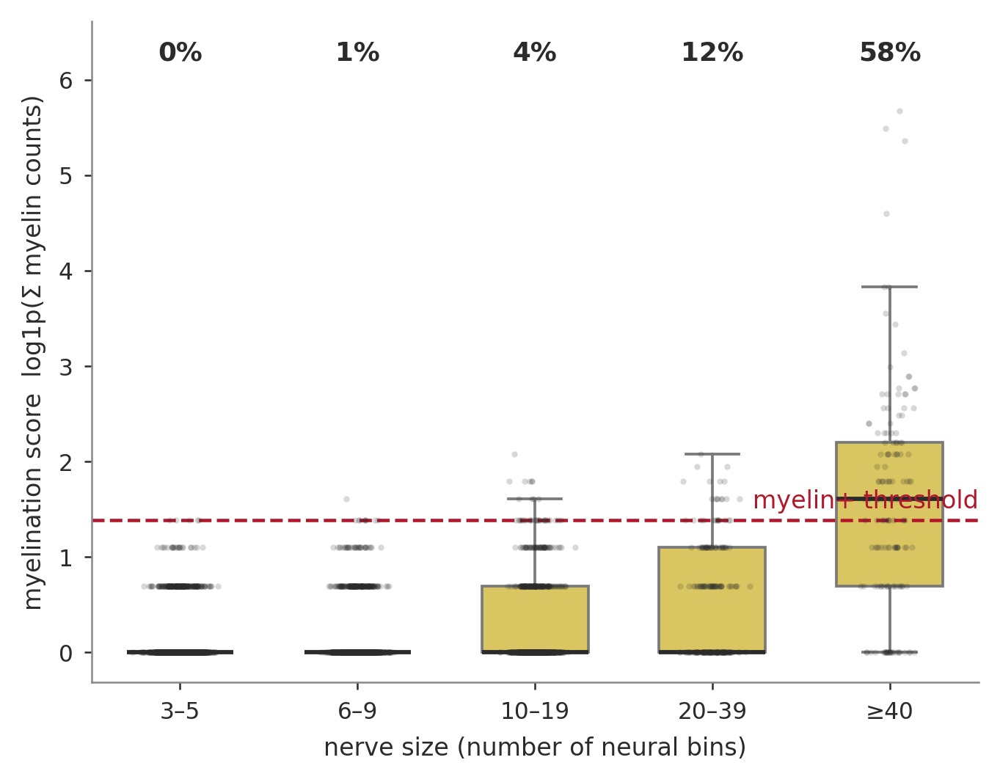

In [25]:
fig = hhca.pl.myelination_by_size(myelination, nerve["size_classes"], nerve["myelinated_min"])

Myelination grows with nerve size: 0.2% of the 2,263 nerves with 3–5 bins are myelinating, 12.3% of those with
20–39 bins and 58.3% of the 151 nerves with at least 40 bins (Spearman ρ = 0.32).

One of the large nerves of our section shows where the myelin counts sit. The field of Fig 5 f is 110 µm around
its centroid. `hhca.tl.local_myelin` sums, for every neural bin of the field, the myelin counts of all bins within
4 µm; a single 2 µm bin holds too few counts to be drawn on its own.

In [26]:
myelin_centre = fields["f"]["centre"]
myelin_side_um = fields["f"]["side_um"]
myelin_window = hhca.tl.square_window(myelin_centre, myelin_side_um)
offset = hhca.tl.registration_offset(
    he,
    um_to_px,
    cytassist,
    cytassist_um_per_px,
    myelin_centre,
    half_um=tile_half_um,
    res_um=resolution_um,
    max_error=max_error,
    max_um=max_shift_um,
)
myelin_field = hhca.tl.registered_field(adata, he, um_to_px, myelin_window, offset["shift"], tissue_xy=tissue_xy)
local_counts = hhca.tl.local_myelin(
    adata,
    myelin_window,
    myelin_genes,
    radius_um=fields["f"]["display_radius_um"],
    neural_type=neural_type,
    neural_bins=neural_bins[section],
)
myelin_field.update(local_counts)
field_bins = pd.DataFrame({"nerve": myelin_field["nnerve"], "myelin counts": myelin_field["nown"]})
field_bins.groupby("nerve").agg(bins=("myelin counts", "size"), myelin_counts=("myelin counts", "sum"))

,bins,myelin_counts
nerve,,
-1,1,0.0
239,85,3.0
244,244,45.0


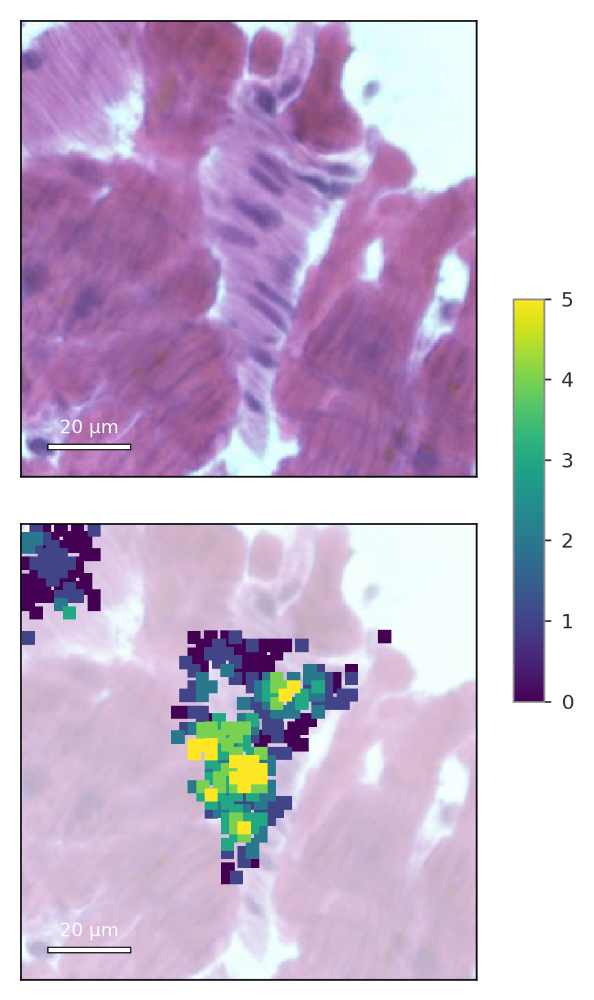

In [27]:
fig = hhca.pl.myelin_on_he(myelin_field)

The field holds two nerves. The larger one, with 244 bins in the field, carries 45 myelin counts along its whole
length; the smaller one, with 85 bins, only 3.

## Targets of neurotoxic drugs in myelinated nerves

Several chemotherapies damage peripheral nerves (chemotherapy-induced peripheral neuropathy, CIPN). If their
targets are expressed in cardiac nerves, is that in the myelinated ones? We compare nerves with clear myelin
counts with nerves that have none. `hhca.tl.myelination_groups` adds the group of every nerve to `nerves.obs`;
nerves with one or two myelin counts are intermediate and left out.

In [28]:
hhca.tl.myelination_groups(nerves, nerve["myelinated_min"])
nerves.obs["group"].value_counts().to_frame("nerves")

,nerves
group,
non_myelinated,3773
intermediate,740
myelinated,165


Small nerves have too few counts for a stable profile, so we keep the nerves with at least 15 bins and 80 counts.
The counts are then scaled to 10,000 per nerve and log-transformed.

In [29]:
drugs = cfg["drugs"]
keep = (
    (nerves.obs["n_bins"] >= drugs["min_bins"])
    & (nerves.obs["total_counts"] >= drugs["min_counts"])
    & (nerves.obs["group"] != "intermediate")
)
compared = nerves[keep].copy()
sc.pp.normalize_total(compared, target_sum=1e4)
sc.pp.log1p(compared)
compared.obs["group"].value_counts().to_frame("nerves")

,nerves
group,
non_myelinated,136
myelinated,135


drug2cell scores a drug as the mean expression of its ChEMBL target genes. The myelin genes define our two
groups, so `hhca.tl.score_drug_targets` removes them from every target set before it runs drug2cell; the scores
of all drugs are stored as `compared.uns["drug2cell"]`.

In [30]:
hhca.tl.score_drug_targets(compared, exclude=myelin_genes)
compared.uns["drug2cell"]

AnnData object with n_obs × n_vars = 271 × 2425
    obs: 'nerve', 'n_bins', 'myelin_total', 'total_counts', 'cx', 'cy', 'd_vessel_um', 'slide', 'group'
    var: 'genes', 'all_genes'

The configuration lists 12 drugs with known peripheral neurotoxicity. `hhca.tl.drug_scores` returns the scores of
those that drug2cell knows and that have a measured target.

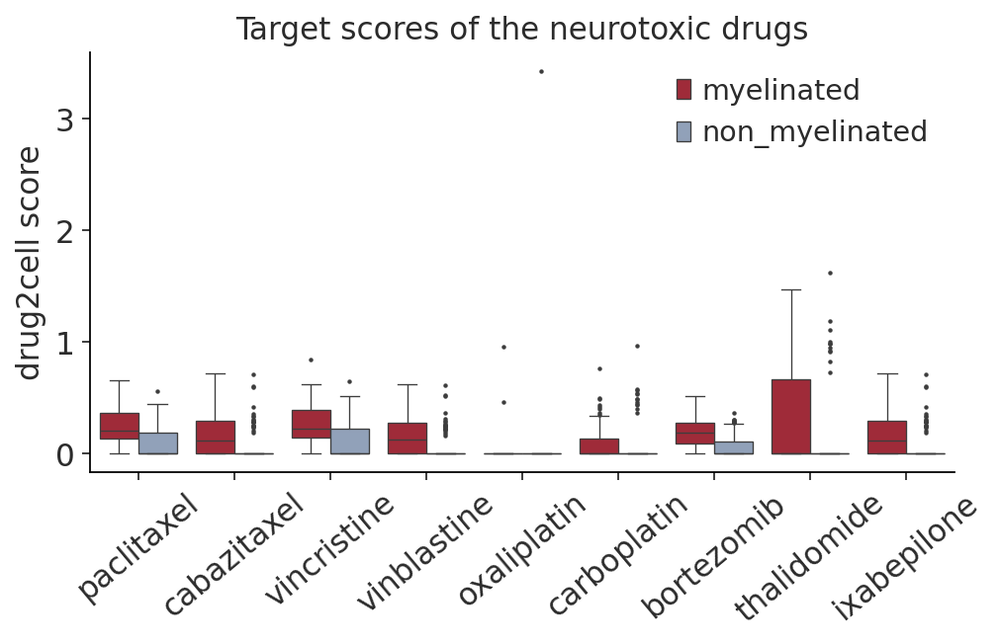

In [31]:
neurotoxic = pd.DataFrame(drugs["h_cipn"], columns=["chembl_id", "drug", "class"]).set_index("chembl_id")
scores = hhca.tl.drug_scores(compared, neurotoxic.index).rename(columns=neurotoxic["drug"])
scores["group"] = compared.obs["group"]
scores_long = scores.melt(id_vars="group", var_name="drug", value_name="score")
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(scores_long, x="drug", y="score", hue="group", palette=style.MYELINATION, fliersize=1, linewidth=0.6, ax=ax)
ax.set(xlabel="", ylabel="drug2cell score")
ax.set_title("Target scores of the neurotoxic drugs")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="")
plt.show()

For one number per nerve, `hhca.tl.mean_drug_score` averages the scores of seven of these drugs, the taxanes,
vinca alkaloids, bortezomib, thalidomide and ixabepilone. We compare the two groups with a one-sided
Mann–Whitney test.

In [32]:
compared.obs["cipn_score"] = hhca.tl.mean_drug_score(compared, drugs["g_chembl"])
nerve_group = compared.obs["group"]
myelinated_scores = compared.obs.loc[nerve_group == "myelinated", "cipn_score"]
non_myelinated_scores = compared.obs.loc[nerve_group == "non_myelinated", "cipn_score"]
higher = stats.mannwhitneyu(myelinated_scores, non_myelinated_scores, alternative="greater")
print(f"one-sided Mann-Whitney U = {higher.statistic:.0f}, p = {higher.pvalue:.1e}")
compared.obs.groupby("group")["cipn_score"].agg(nerves="size", median_score="median").round(3)

one-sided Mann-Whitney U = 14666, p = 7.8e-18


,nerves,median_score
group,,
myelinated,135,0.184
non_myelinated,136,0.041


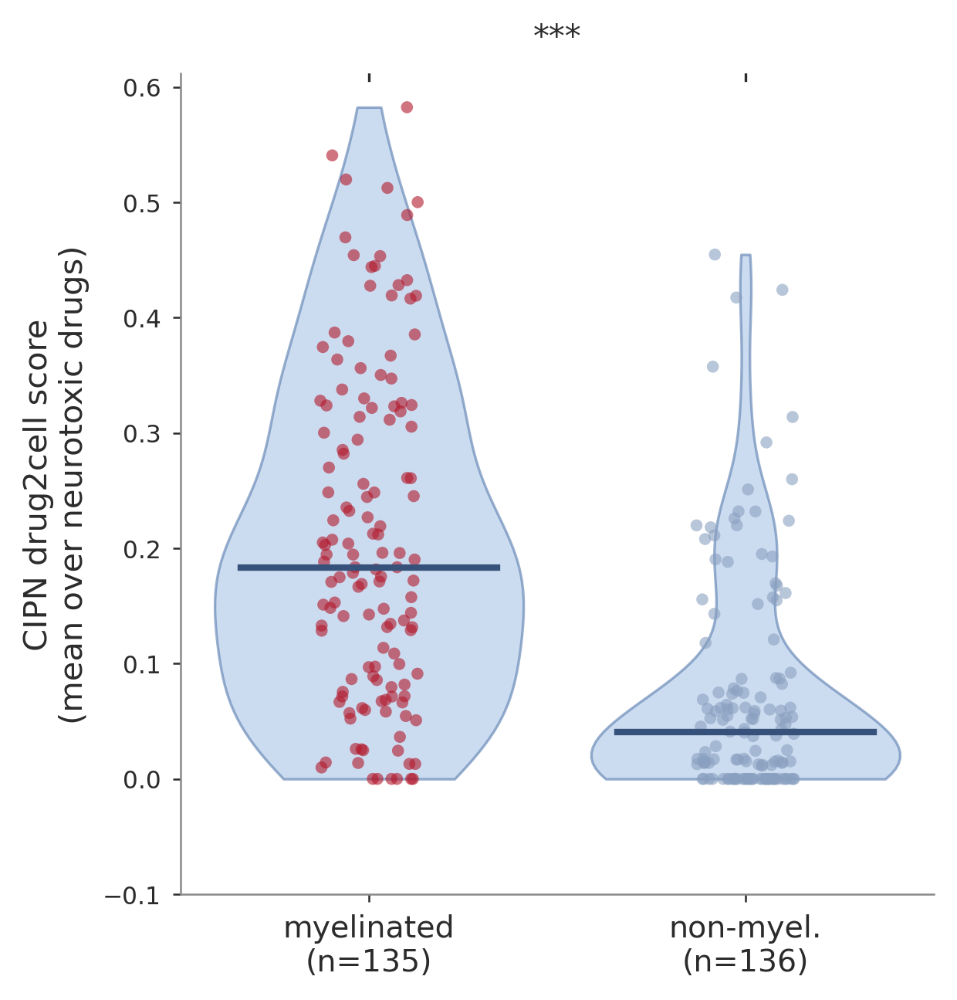

In [33]:
fig = hhca.pl.neurotoxic_score(compared.obs, higher.pvalue)

`hhca.tl.drug_differences` makes the same comparison for every drug on its own: the difference of the mean
scores, a two-sided Mann–Whitney test and the Benjamini–Hochberg adjustment over the drugs. It also lists the
targets that are detected in at least 10% of the nerves.

In [34]:
per_drug = hhca.tl.drug_differences(
    compared, drugs["h_cipn"], exclude=myelin_genes, detected_frac=drugs["detected_frac"]
)
per_drug[["drug", "cls", "in_d2c", "n_targets", "n_detected", "detected_genes", "diff", "fdr"]]

,drug,cls,in_d2c,n_targets,n_detected,detected_genes,diff,fdr
0,paclitaxel,taxane,True,21,3,"LMNA,ITGAV,TUBB2B",0.128507,8.682600e-10
1,docetaxel,taxane,False,0,0,,NaN,NaN
2,cabazitaxel,taxane,True,13,1,TUBB2B,0.110154,1.186660e-09
3,vincristine,vinca,True,18,2,"LMNA,TUBB2B",0.136979,1.186660e-09
4,vinblastine,vinca,True,15,1,TUBB2B,0.098017,1.186660e-09
5,cisplatin,platinum,False,0,0,,NaN,NaN
6,oxaliplatin,platinum,True,1,0,,-0.014748,5.665913e-01
7,carboplatin,platinum,True,8,1,APEX1,0.034440,5.306272e-04
8,bortezomib,proteasome,True,39,5,"EPAS1,PSMD6,PSMB1,PSMD3,PSMC5",0.126828,1.479910e-15
9,thalidomide,IMiD,True,4,2,"DDB1,RBX1",0.235729,1.186660e-09


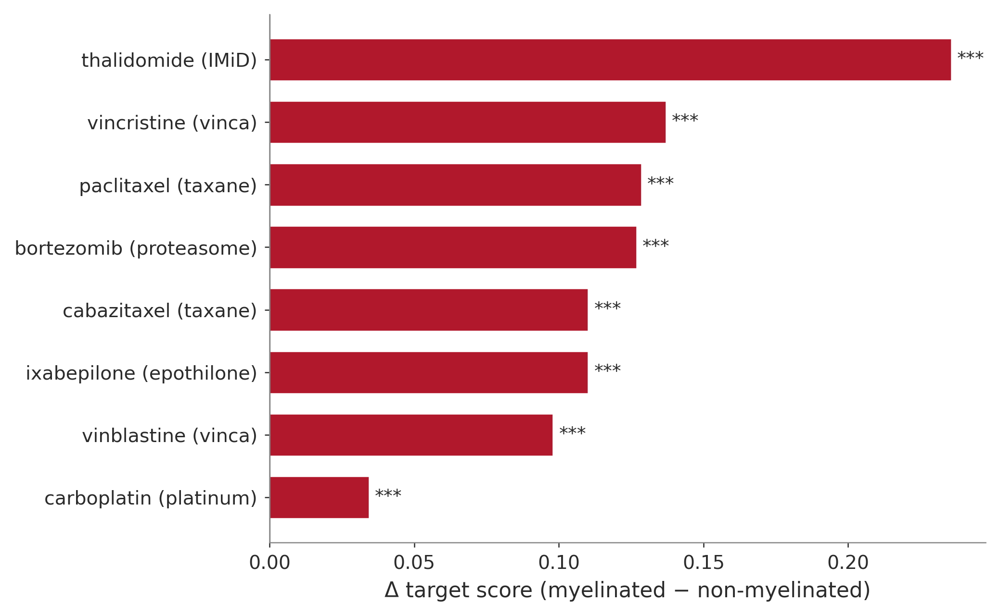

In [35]:
fig = hhca.pl.neurotoxic_drugs(per_drug)

The 135 myelinated nerves score higher than the 136 non-myelinated ones (median 0.184 against 0.041,
p = 7.8e-18). Eight drugs have a target that is detected in nerves, and all eight score higher in myelinated
nerves (adjusted p < 0.05), most of all thalidomide (*DDB1*, *RBX1*). Oxaliplatin has no detected target and does
not differ; docetaxel, cisplatin and eribulin are not in the drug2cell dictionary.

## Macrophages on the histology

Macrophages are the most frequent immune cells of the myocardium, and they are known to line both vessels and
nerves. Before we count them, we look at two fields of 300 µm of our section, one in the myocardium and one
around a nerve, with the bins of macrophages and of four vascular types.

In [36]:
shown_types = fields["j"]["show"]
macrophage_fields = []
bins_per_field = {}
for name, field_cfg in fields["j"]["fields"].items():
    offset = hhca.tl.registration_offset(
        he,
        um_to_px,
        cytassist,
        cytassist_um_per_px,
        field_cfg["centre"],
        half_um=tile_half_um,
        res_um=resolution_um,
        max_error=max_error,
        max_um=max_shift_um,
    )
    window = hhca.tl.square_window(field_cfg["centre"], field_cfg["side_um"])
    field = hhca.tl.registered_field(adata, he, um_to_px, window, offset["shift"], tissue_xy=tissue_xy)
    macrophage_fields.append(field)
    bins_per_field[name] = pd.Series(field["blab"]).value_counts()
pd.DataFrame(bins_per_field).loc[shown_types].astype(int)

,myeloid_peri,myeloid_nerve
Macrophages,295,164
Capillary Endothelial cells,249,129
Pericytes,945,241
Vascular Smooth Muscle cells,102,847
Arterial Endothelial cells,157,154


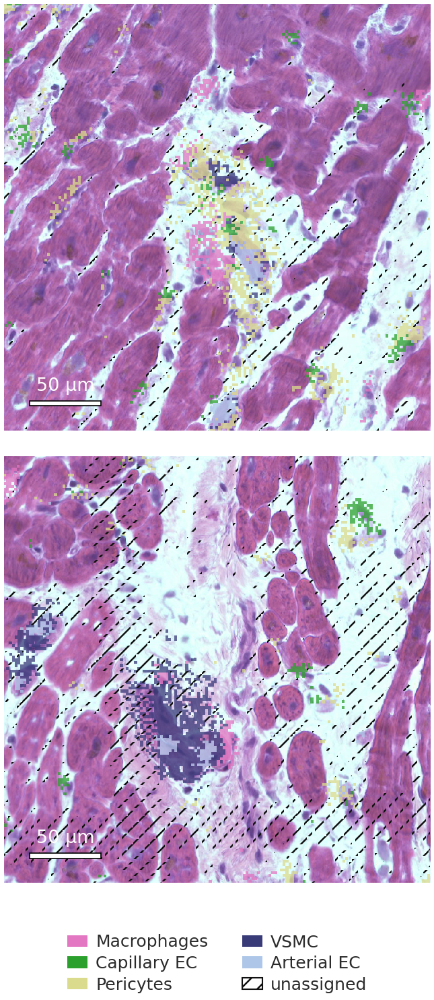

In [37]:
fig = hhca.pl.macrophage_fields(macrophage_fields, shown_types)

The two fields hold 295 and 164 macrophage bins. They form small groups between the cardiomyocytes, many of them
next to capillaries and pericytes.

## Macrophage pseudo-cells

To compare macrophages we need units with enough counts. A macrophage covers several 2 µm bins, so we join
neighbouring macrophage pixels of the decode into **pseudo-cells**. The counts come from the Space Ranger matrix of
all in-tissue bins, which we load for our section together with its decode.

In [38]:
macrophage = cfg["macrophage"]
with open(section_path(cfg, "factor_order")) as handle:
    factor_order = json.load(handle)
macrophage_factor = factor_order.index(macrophage["cell_type"])
pixels = hhca.io.read_decode(section_path(cfg, "decode", section))
bins = hhca.io.read_visium_hd(section_path(cfg, "spaceranger", section))
bins.var_names_make_unique()
n_macrophage_pixels = (pixels["K1"] == macrophage_factor).sum()
print(f"{n_macrophage_pixels:,} of {len(pixels):,} decode pixels are macrophage pixels")
bins

35,944 of 6,930,447 decode pixels are macrophage pixels


AnnData object with n_obs × n_vars = 4273635 × 18085
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'microns_per_pixel'
    obsm: 'spatial'

`hhca.tl.pseudocells` clusters the macrophage pixels (DBSCAN, 10 µm, at least three pixels), cuts clusters of
more than 50 pixels into tiles of 12 µm, sums the counts of the bins under each group of pixels and keeps the
groups with at least 100 counts.

In [39]:
pseudocell_cfg = macrophage["pseudocells"]
pd.Series(pseudocell_cfg, name="value").to_frame()

,value
eps_um,10.0
min_pixels,3.0
split_pixels,50.0
tile_um,12.0
min_counts,100.0


In [40]:
cells = hhca.tl.pseudocells(
    bins,
    pixels,
    macrophage_factor,
    eps_um=pseudocell_cfg["eps_um"],
    min_pixels=pseudocell_cfg["min_pixels"],
    split_pixels=pseudocell_cfg["split_pixels"],
    tile_um=pseudocell_cfg["tile_um"],
    min_counts=pseudocell_cfg["min_counts"],
)
cells

AnnData object with n_obs × n_vars = 1333 × 18085
    obs: 'centroid_x_um', 'centroid_y_um', 'n_bins', 'total_counts'

In [41]:
cells.obs.describe().loc[["mean", "50%", "max"]].round(1)

,centroid_x_um,centroid_y_um,n_bins,total_counts
mean,4577.6,7108.0,14.0,382.9
50%,4654.9,7011.8,12.0,300.0
max,7439.7,9336.5,47.0,1782.0


We build the pseudo-cells of every section in the same way. For each of them `hhca.tl.nearest_structure` looks
up the nearest vessel structure in the calibre table of the vessel analysis and adds its distance, diameter and
calibre class.

In [42]:
calibre = pd.read_csv(section_path(cfg, "caliber"))
cells_by_section = {}
for name in section_names:
    bins = hhca.io.read_visium_hd(section_path(cfg, "spaceranger", name))
    bins.var_names_make_unique()
    pixels = hhca.io.read_decode(section_path(cfg, "decode", name))
    cells_by_section[name] = hhca.tl.pseudocells(
        bins,
        pixels,
        macrophage_factor,
        eps_um=pseudocell_cfg["eps_um"],
        min_pixels=pseudocell_cfg["min_pixels"],
        split_pixels=pseudocell_cfg["split_pixels"],
        tile_um=pseudocell_cfg["tile_um"],
        min_counts=pseudocell_cfg["min_counts"],
    )
    structures_of_section = calibre[calibre["slide"] == name]
    hhca.tl.nearest_structure(cells_by_section[name].obs, structures_of_section)
cells = ad.concat(cells_by_section, label="slide", index_unique="__")
del bins, pixels
n_sections = cells.obs["slide"].nunique()
print(f"{cells.n_obs:,} pseudo-cells on {n_sections} sections, {cells.n_vars:,} genes")
cells.obs.groupby("slide", observed=True)["total_counts"].agg(pseudocells="size", median_counts="median")

8,392 pseudo-cells on 11 sections, 18,085 genes


,pseudocells,median_counts
slide,,
VS_BO_HDZ150319_34_myo,1333,300.0
VS_BO_2024BH-008_myo,101,164.0
VS_CA_H0054LV_henricke_epi,703,194.0
VS_CA_H0054LV_henricke_myo,1099,202.0
VS_CA_H0054LV_henricke_endo,1568,261.0
VS_CA_H0063LV_henricke_epi,859,203.0
VS_CA_H0063LV_henricke_myo,824,218.0
VS_CA_H0063LV_henricke_endo,706,218.0
VS_AH9_LV_FW_epi,722,182.0


The 11 sections give 8,392 macrophage pseudo-cells.

## Perineural macrophages

Which of them sit next to a nerve? `hhca.tl.nerve_distance` measures the distance from every pseudo-cell to the
nearest neural bin. It does so for several definitions of a nerve: `dist_nerve_k3` only counts neural bins that
are linked with at least three bins, the nerves we called above, while `dist_nerve_k1` counts every neural bin
and `k5` and `k10` only larger nerves. The table it returns shows how many neural bins and nerves each definition
keeps.

In [43]:
retention = hhca.tl.nerve_distance(cells.obs, neural_bins, macrophage["nerve_min_sizes"])
retention.set_index("slide")

,n_neural,n_components,n_bins_k1,n_nerves_k1,n_bins_k3,n_nerves_k3,n_bins_k5,n_nerves_k5,n_bins_k10,n_nerves_k10
slide,,,,,,,,,,
VS_BO_HDZ150319_34_myo,5569,702,5569,702,5111,312,4880,243,4126,130
VS_BO_2024BH-008_myo,553,161,553,161,406,42,353,26,274,13
VS_CA_H0054LV_henricke_epi,3360,707,3360,707,2799,284,2392,164,1752,63
VS_CA_H0054LV_henricke_myo,3108,655,3108,655,2637,300,2173,164,1512,65
VS_CA_H0054LV_henricke_endo,8851,958,8851,958,8290,519,7813,376,6557,186
VS_CA_H0063LV_henricke_epi,1429,266,1429,266,1238,122,1075,73,780,25
VS_CA_H0063LV_henricke_myo,3300,319,3300,319,3086,160,2918,108,2444,36
VS_CA_H0063LV_henricke_endo,9520,632,9520,632,9128,334,8745,221,7962,101
VS_AH9_LV_FW_epi,9948,1911,9948,1911,8670,949,7388,580,4814,180


A pseudo-cell is **perineural** when its centroid lies within 30 µm of a nerve; all others are perivascular or
interstitial.

In [44]:
perineural = cells.obs[macrophage["dist_col"]] < macrophage["perineural_um"]
cells.obs["niche"] = pd.Categorical(np.where(perineural, "perineural", "rest"), categories=["perineural", "rest"])
per_section = pd.crosstab(cells.obs["slide"], cells.obs["niche"])
per_section["% perineural"] = (100 * per_section["perineural"] / per_section.sum(axis=1)).round(1)
per_section

niche,perineural,rest,% perineural
slide,,,
VS_BO_HDZ150319_34_myo,196,1137,14.7
VS_BO_2024BH-008_myo,8,93,7.9
VS_CA_H0054LV_henricke_epi,45,658,6.4
VS_CA_H0054LV_henricke_myo,65,1034,5.9
VS_CA_H0054LV_henricke_endo,203,1365,12.9
VS_CA_H0063LV_henricke_epi,27,832,3.1
VS_CA_H0063LV_henricke_myo,22,802,2.7
VS_CA_H0063LV_henricke_endo,52,654,7.4
VS_AH9_LV_FW_epi,137,585,19.0


On our section, the perineural pseudo-cells follow the nerves:

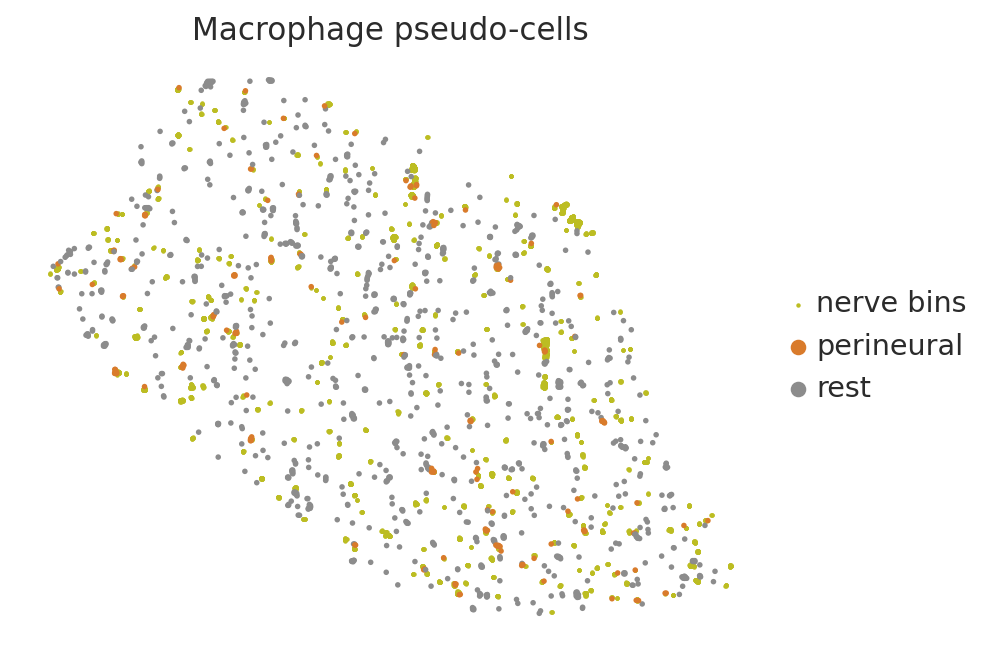

In [45]:
on_section = cells[cells.obs["slide"] == section].copy()
on_section.obsm["spatial"] = on_section.obs[["centroid_x_um", "centroid_y_um"]].to_numpy()
style.set_colors(on_section, "niche", style.NICHE)
section_neural_bins = neural_bins[section]
nerve_bins = section_neural_bins[section_neural_bins["nerve"] >= 0]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(nerve_bins["x_um"], nerve_bins["y_um"], s=1, color=style.SPATIAL[neural_type], label="nerve bins")
sc.pl.embedding(on_section, basis="spatial", color="niche", size=25, title="Macrophage pseudo-cells", ax=ax, show=False)
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

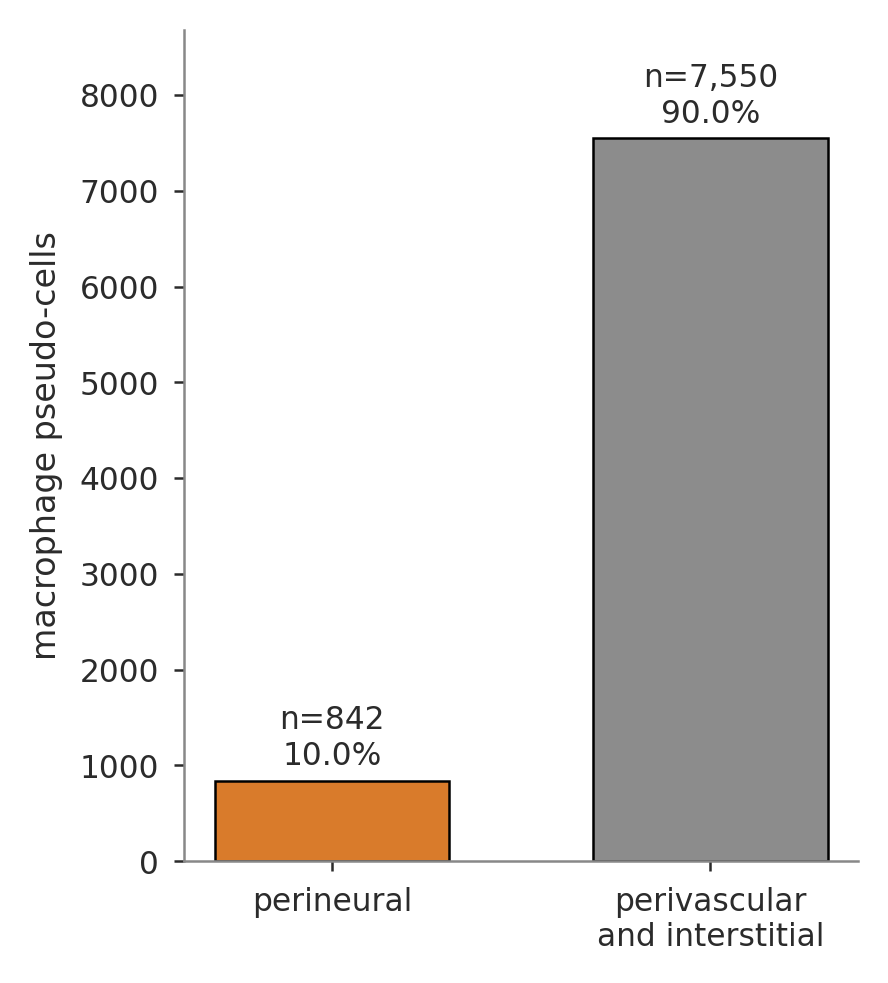

In [46]:
n_perineural = int(perineural.sum())
n_other = int((~perineural).sum())
fig = hhca.pl.perineural_counts(n_perineural, n_other)

842 of the 8,392 pseudo-cells (10.0%) are perineural. The share differs between sections, from 2.7% to 29.5%,
so every comparison below is adjusted for the section.

## Markers of perineural macrophages

Do perineural macrophages express other genes? We start with a Wilcoxon test of every gene between the two
niches, on counts scaled to 10,000 per pseudo-cell and log-transformed.

In [47]:
normalised = cells.copy()
sc.pp.normalize_total(normalised, target_sum=1e4)
sc.pp.log1p(normalised)
sc.tl.rank_genes_groups(normalised, "niche", groups=["perineural"], reference="rest", method="wilcoxon")
ranked = sc.get.rank_genes_groups_df(normalised, group="perineural")
ranked.head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,VIM,8.790003,1.091781,1.495558e-18,3.380895e-15
1,TMSB4X,5.105181,0.585412,3.304773e-07,3.145622e-04
2,ACTB,4.188666,0.517877,2.805987e-05,2.114428e-02
3,MGP,3.768737,0.870785,1.640756e-04,1.141272e-01
4,SPP1,2.743674,1.666266,6.075581e-03,1.000000e+00
5,S100A10,2.614386,0.917948,8.938810e-03,1.000000e+00
6,COL1A2,2.606640,0.835892,9.143553e-03,1.000000e+00
7,COL3A1,2.580995,0.759737,9.851604e-03,1.000000e+00
8,SPARC,2.564813,0.574890,1.032314e-02,1.000000e+00
9,TAGLN,2.513209,0.783175,1.196385e-02,1.000000e+00


Three genes pass the adjustment over all 18,085 genes, *VIM*, *TMSB4X* and *ACTB*; the next ones are genes of the
vessel wall and the matrix (*MGP*, collagens, *TAGLN*), which a pseudo-cell next to a nerve and its vessel picks
up, and *SPP1* in fifth place. This test pools all sections and does not know how many nerves each of them has. We
therefore ask a narrower question, for six macrophage genes that describe known states: *SPP1*, the
tissue-resident markers *LYVE1*, *F13A1*, *MRC1* and *FOLR2*, and *C1QA*.

In [48]:
ranked.set_index("names").loc[macrophage["markers"]]

,scores,logfoldchanges,pvals,pvals_adj
names,,,,
SPP1,2.743674,1.666266,0.006076,1.0
LYVE1,-2.606497,-0.368230,0.009147,1.0
F13A1,-2.157436,-0.325548,0.030972,1.0
C1QA,-2.519005,-0.367495,0.011769,1.0
MRC1,-1.669706,-0.282784,0.094978,1.0
FOLR2,0.419787,0.100903,0.674641,1.0


For the model, `hhca.tl.marker_expression` returns the expression of the six genes per pseudo-cell. We add the
section, the niche as a 0/1 indicator and the library size as a z-score of the log counts.

In [49]:
expression = hhca.tl.marker_expression(cells, macrophage["regression_markers"])
design = pd.concat([cells.obs[["slide", "niche"]], expression], axis=1)
design["peri"] = (design["niche"] == "perineural").astype(int)
design["logcounts"] = np.log(cells.obs["total_counts"].astype(float))
log_counts = design["logcounts"]
design["z_lc"] = (log_counts - log_counts.mean()) / log_counts.std()
design[["slide", "niche", "peri", "z_lc", "SPP1_raw", "SPP1_log1p_cp10k", "SPP1_det"]].head()

,slide,niche,peri,z_lc,SPP1_raw,SPP1_log1p_cp10k,SPP1_det
0__VS_BO_HDZ150319_34_myo,VS_BO_HDZ150319_34_myo,rest,0,0.058519,0.0,0.0,0
1__VS_BO_HDZ150319_34_myo,VS_BO_HDZ150319_34_myo,rest,0,-0.150530,0.0,0.0,0
2__VS_BO_HDZ150319_34_myo,VS_BO_HDZ150319_34_myo,rest,0,-0.679929,0.0,0.0,0
3__VS_BO_HDZ150319_34_myo,VS_BO_HDZ150319_34_myo,rest,0,1.329513,0.0,0.0,0
4__VS_BO_HDZ150319_34_myo,VS_BO_HDZ150319_34_myo,rest,0,-0.090182,0.0,0.0,0


For *SPP1* the model is an ordinary least-squares regression of the expression on the indicator, the library
size and the section, with robust (HC3) standard errors:

In [50]:
fit = smf.ols("SPP1_log1p_cp10k ~ peri + z_lc + C(slide)", data=design).fit(cov_type="HC3")
beta = fit.params["peri"]
ci_low, ci_high = fit.conf_int().loc["peri"]
p_value = fit.pvalues["peri"]
print(f"perineural effect on SPP1: {beta:.3f} (95% CI {ci_low:.3f} to {ci_high:.3f}), p = {p_value:.1e}")

perineural effect on SPP1: 0.221 (95% CI 0.129 to 0.313), p = 2.5e-06


`hhca.tl.marker_effects` fits the same model for every marker and adjusts the p values over the markers
(Benjamini–Hochberg).

In [51]:
effects = hhca.tl.marker_effects(design, macrophage["regression_markers"], "peri")
effects_table = effects.round(4)
effects_table["p"] = effects["p"].map("{:.1e}".format)
effects_table["padj"] = effects["padj"].map("{:.1e}".format)
effects_table

,marker,beta,ci_lo,ci_hi,p,padj,n,r2
0,SPP1,0.2211,0.1291,0.3132,2.5e-06,1.5e-05,8392,0.0867
1,LYVE1,-0.1142,-0.2571,0.0287,1.2e-01,2.3e-01,8392,0.0614
2,F13A1,-0.1100,-0.2651,0.0450,1.6e-01,2.5e-01,8392,0.0619
3,MRC1,-0.0542,-0.1782,0.0697,3.9e-01,4.7e-01,8392,0.0415
4,C1QA,-0.1347,-0.2787,0.0093,6.7e-02,2.0e-01,8392,0.0788
5,FOLR2,0.0058,-0.0947,0.1063,9.1e-01,9.1e-01,8392,0.0348


Is the *SPP1* difference there on every section? `hhca.tl.marker_means` gives the mean expression in the two
niches per section, without any adjustment.

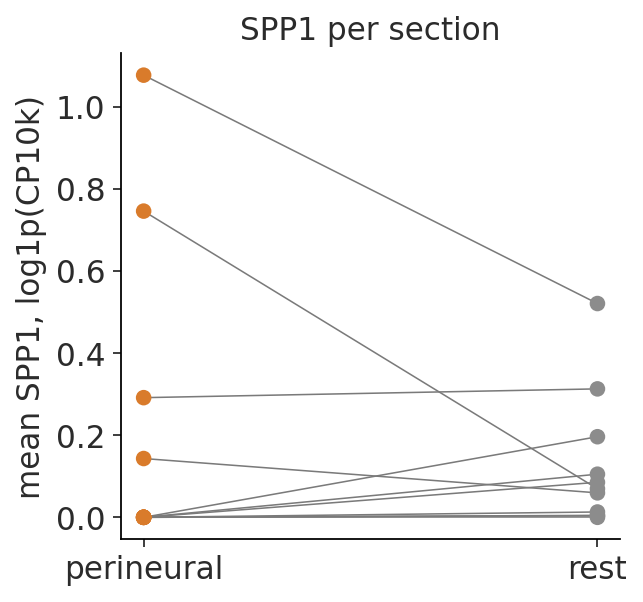

SPP1 is higher in perineural pseudo-cells on 3 of 11 sections


In [52]:
means = hhca.tl.marker_means(design, ["SPP1"])
means_long = means.melt(
    id_vars="slide", value_vars=["mean_perineural", "mean_other"], var_name="niche", value_name="mean SPP1"
)
niche_of_column = {"mean_perineural": "perineural", "mean_other": "rest"}
means_long["niche"] = means_long["niche"].map(niche_of_column)
ax = sns.stripplot(means_long, x="niche", y="mean SPP1", hue="niche", palette=style.NICHE, size=7, jitter=False)
for _, row in means.iterrows():
    ax.plot([0, 1], [row["mean_perineural"], row["mean_other"]], color=style.MUTED, lw=0.7, zorder=0)
ax.set(xlabel="", ylabel="mean SPP1, log1p(CP10k)")
ax.set_title("SPP1 per section")
plt.show()
higher_near_nerves = (means["mean_perineural"] > means["mean_other"]).sum()
print(f"SPP1 is higher in perineural pseudo-cells on {higher_near_nerves} of {len(means)} sections")

In [53]:
means.sort_values("mean_perineural", ascending=False)[
    ["slide", "n_perineural", "n_other", "mean_perineural", "mean_other"]
].round(2)

,slide,n_perineural,n_other,mean_perineural,mean_other
0,VS_BO_HDZ150319_34_myo,196,1137,1.08,0.52
8,VS_AH9_LV_FW_epi,137,585,0.75,0.07
4,VS_CA_H0054LV_henricke_endo,203,1365,0.29,0.31
5,VS_CA_H0063LV_henricke_epi,27,832,0.14,0.06
1,VS_BO_2024BH-008_myo,8,93,0.00,0.20
2,VS_CA_H0054LV_henricke_epi,45,658,0.00,0.00
3,VS_CA_H0054LV_henricke_myo,65,1034,0.00,0.09
6,VS_CA_H0063LV_henricke_myo,22,802,0.00,0.00
7,VS_CA_H0063LV_henricke_endo,52,654,0.00,0.00
9,VS_AH10_LV_mid_endo,54,311,0.00,0.01


`hhca.pl.perineural_markers` draws Fig 5 l: the adjusted difference of each marker.

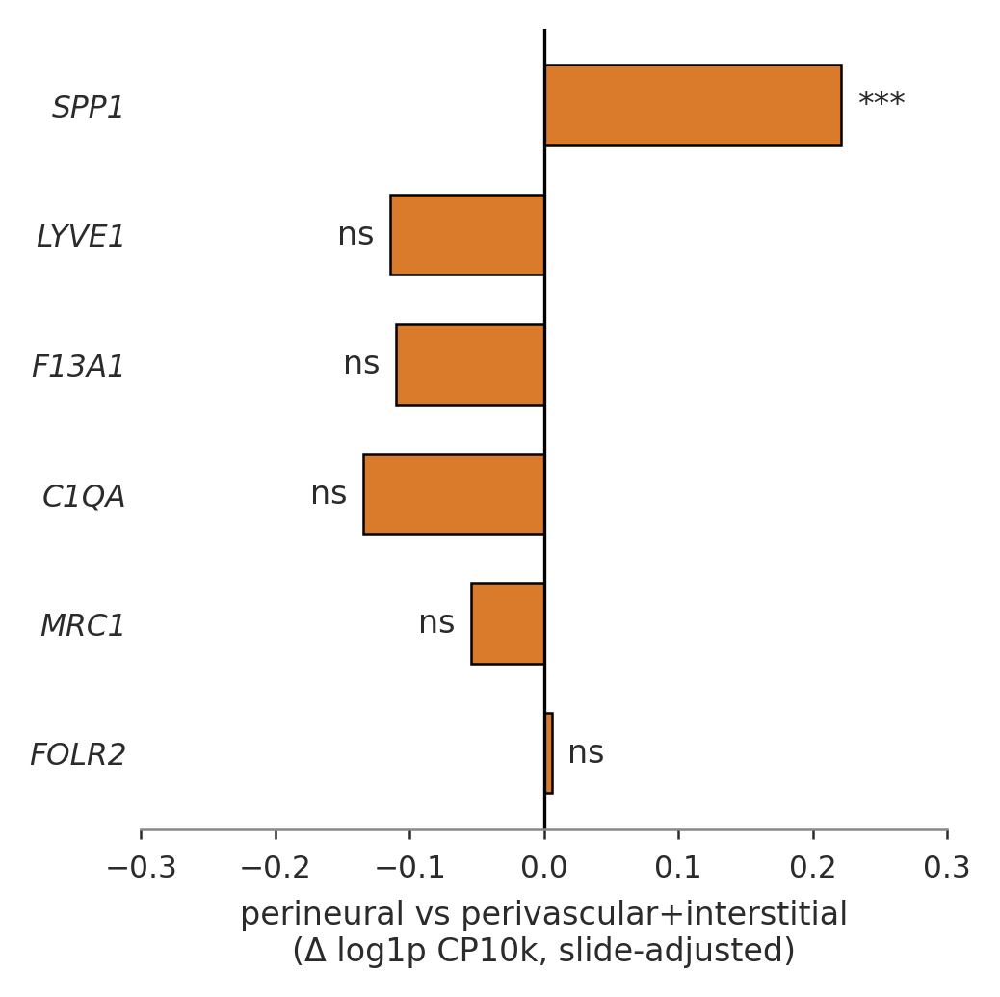

In [54]:
fig = hhca.pl.perineural_markers(effects, macrophage["markers"])

In the section-adjusted model perineural macrophages express more *SPP1*: 0.221 log1p CP10k above the other
macrophages (95% CI 0.129 to 0.313, adjusted p = 1.5e-05). The five other markers do not differ after adjustment
(adjusted p ≥ 0.20). The *SPP1* difference is not spread evenly over the sections, however: the unadjusted mean is
higher in perineural pseudo-cells on 3 of 11 sections, and two of them, `VS_BO_HDZ150319_34_myo` (1.08 against
0.52) and `VS_AH9_LV_FW_epi` (0.75 against 0.07), carry the effect. On seven sections no perineural pseudo-cell
has an *SPP1* count at all.

## How much depends on the definition of a nerve?

Two things could produce this result without perineural macrophages being special: stray neural bins that are
not nerves, and vessels, since nerves run along them. For the first, we regress *SPP1* on the distance to the
nearest nerve for each of the four nerve definitions; a negative slope means more *SPP1* near nerves.

In [55]:
slope_tables = {}
for min_size in macrophage["nerve_min_sizes"]:
    with_distance = design.copy()
    with_distance["z_dn"] = stats.zscore(cells.obs[f"dist_nerve_k{min_size}"], ddof=1)
    slope_tables[min_size] = hhca.tl.marker_effects(with_distance, ["SPP1"], "z_dn")
slopes = pd.concat(slope_tables, names=["min bins per nerve"]).droplevel(1)
slopes_table = slopes[["beta", "ci_lo", "ci_hi"]].round(4)
slopes_table["p"] = slopes["p"].map("{:.1e}".format)
slopes_table

,beta,ci_lo,ci_hi,p
min bins per nerve,,,,
1,-0.0947,-0.1112,-0.0783,1.6e-29
3,-0.0391,-0.0542,-0.0241,3.3e-07
5,-0.0310,-0.0458,-0.0163,3.8e-05
10,0.0027,-0.0171,0.0225,7.9e-01


For the second, we add the nearest vessel structure to the model: its distance and its calibre class.

In [56]:
calibre_rank = cells.obs["class_near"].map(macrophage["calibre_rank"]).astype(float)
design["z_dv"] = stats.zscore(cells.obs["dist_vessel_struct_um"], ddof=1)
design["z_cal"] = stats.zscore(calibre_rank, ddof=1)
adjusted = hhca.tl.marker_effects(design, ["SPP1"], "peri", adjust=("z_dv", "z_cal", "z_lc"))
adjusted_table = adjusted[["marker", "beta", "ci_lo", "ci_hi"]].round(4)
adjusted_table["p"] = adjusted["p"].map("{:.1e}".format)
adjusted_table

,marker,beta,ci_lo,ci_hi,p
0,SPP1,0.2294,0.1377,0.3211,9.4e-07


The slope is steepest when every neural bin counts as a nerve (−0.095 per standard deviation of the distance),
less than half as steep for nerves of at least three (−0.039) or five bins (−0.031), where it stays significant,
and absent for nerves of at least ten bins (0.003, p = 0.79). The perineural difference itself does not change when
the nearest vessel is taken into account (0.229 against 0.221).

## Key takeaways

- Linking neural 2 µm bins gives 4,678 nerves on 11 sections; most are a few bins large.
- Nerves run along vessels: half of them lie within 4.5 µm of a vascular bin, against 20.4 µm for the same
  shapes at random positions.
- Myelination grows with nerve size, from 0.2% of the smallest to 58.3% of the largest nerves.
- Myelinated nerves express more targets of neurotoxic chemotherapies, for all eight drugs with a detected
  target.
- One in ten macrophage pseudo-cells is perineural; in the section-adjusted model they express more *SPP1* than
  the other macrophages, a difference that two of the 11 sections carry.
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.